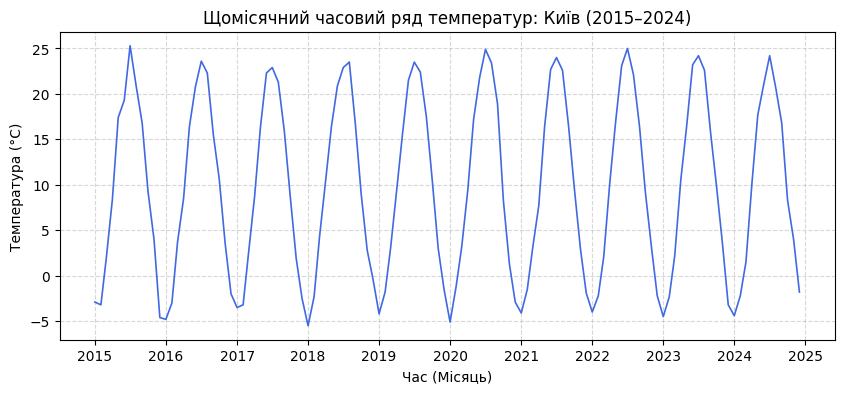

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import linregress

# Генерація часового ряду для Варіанта 1 (Київ)
np.random.seed(1)
base_temp = 9.5
amplitude = 14
trend_per_year = 0.04
noise_scale = 1.0
city = "Київ"
n_years = 10

dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12   # роки від початку ряду
seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)   # річний цикл (пік влітку)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend + seasonal + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")

# Побудова графіка вихідного ряду
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, color="royalblue", linewidth=1.2)
ax.set_xlabel("Час (Місяць)")
ax.set_ylabel("Температура (°C)")
ax.set_title(f"Щомісячний часовий ряд температур: {city} (2015–2024)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

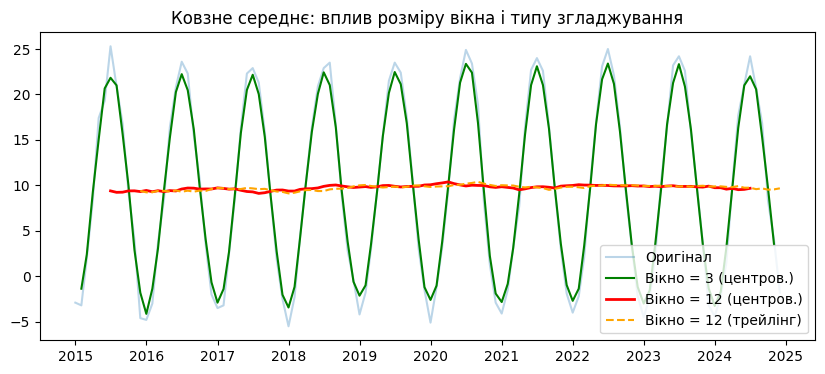

In [121]:
# Завдання 2. Ковзне середнє
ma3 = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12, center=False).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.3, label="Оригінал")
ax.plot(climate_ts.index, ma3.values, label="Вікно = 3 (центров.)", color="green")
ax.plot(climate_ts.index, ma12_centered.values, label="Вікно = 12 (центров.)", color="red", linewidth=2)
ax.plot(climate_ts.index, ma12_trailing.values, label="Вікно = 12 (трейлінг)", linestyle="--", color="orange")
ax.legend()
ax.set_title("Ковзне середнє: вплив розміру вікна і типу згладжування")
plt.show()

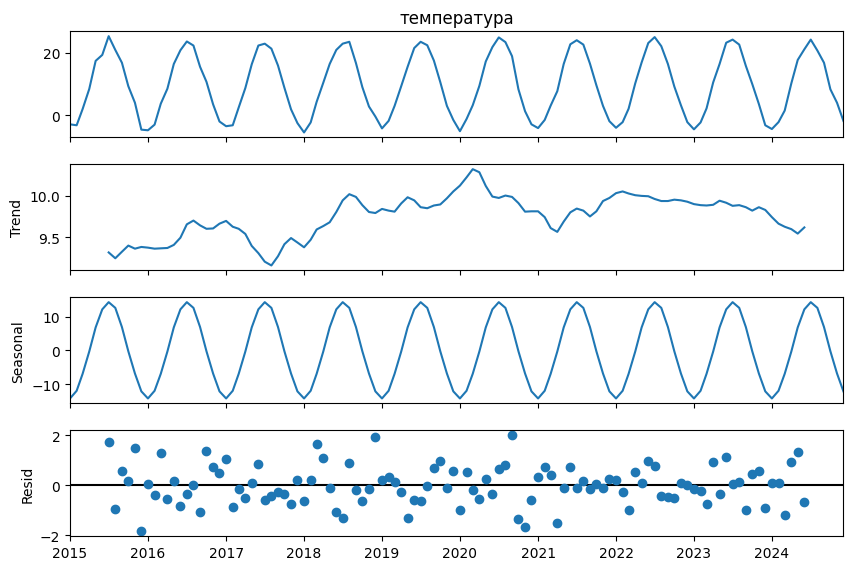

Стандартне відхилення залишків (resid): 0.787
Оцінений сезонний профіль за місяцями:
 2015-01-01   -14.24
2015-02-01   -11.97
2015-03-01    -6.93
2015-04-01    -0.34
2015-05-01     6.81
2015-06-01    12.15
2015-07-01    14.28
2015-08-01    12.59
2015-09-01     6.91
2015-10-01    -0.26
2015-11-01    -6.85
2015-12-01   -12.14
Freq: MS, Name: seasonal, dtype: float64


In [122]:
# Завдання 3. Формальна декомпозиція
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(9, 6)
plt.show()

print(f"Стандартне відхилення залишків (resid): {decomposition.resid.dropna().std():.3f}")
print("Оцінений сезонний профіль за місяцями:\n", decomposition.seasonal.head(12).round(2))

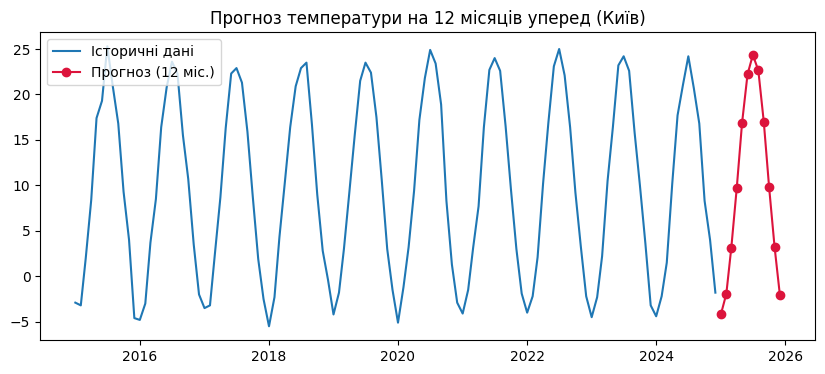

Значення прогнозу:
 2025-01-01    -4.2
2025-02-01    -1.9
2025-03-01     3.1
2025-04-01     9.7
2025-05-01    16.9
2025-06-01    22.2
2025-07-01    24.3
2025-08-01    22.7
2025-09-01    17.0
2025-10-01     9.8
2025-11-01     3.2
2025-12-01    -2.0
Freq: MS, Name: прогноз, dtype: float64


In [123]:
# Завдання 4. Прогноз на n_ahead місяців уперед
t = np.arange(len(climate_ts))
known = decomposition.trend.notna().values
fit = linregress(t[known], decomposition.trend[known])

n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = fit.intercept + fit.slope * t_future

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).values
forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates, name="прогноз")

# Графік історії та прогнозу
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, label="Історичні дані")
ax.plot(forecast.index, forecast.values, label="Прогноз (12 міс.)", color="crimson", marker="o")
ax.legend()
ax.set_title("Прогноз температури на 12 місяців уперед (Київ)")
plt.show()

print("Значення прогнозу:\n", forecast.round(1))

In [124]:
# Завдання 5. Статистична перевірка значущості нахилу
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)

print(f"Оцінений нахил slope = {trend_test.slope:.4f} °C/рік")
print(f"Стандартна похибка stderr = {trend_test.stderr:.4f}")
print(f"p-value = {trend_test.pvalue:.4f}")

# 95% довірчий інтервал для нахилу
ci_low = trend_test.slope - 1.96 * trend_test.stderr
ci_high = trend_test.slope + 1.96 * trend_test.stderr
print(f"95% довірчий інтервал для нахилу: ({ci_low:.4f}, {ci_high:.4f})")

Оцінений нахил slope = 0.0473 °C/рік
Стандартна похибка stderr = 0.0274
p-value = 0.0873
95% довірчий інтервал для нахилу: (-0.0065, 0.1010)


### Відповіді на контрольні запитання:

1. **Чому часовий ряд не можна аналізувати звичайними методами незалежних вибірок:**
   - Елементи часового ряду впорядковані в часі й зазвичай мають сильну автокореляцію (сусідні місяці тісно пов'язані між собою), що порушує класичну вимогу незалежності спостережень у статистичних тесті.

2. **Проблема замалого та завеликого вікна ковзного середнього:**
   - Замале вікно погано згладжує випадковий шум і залишає сезонні коливання. Завелике вікно спотворює і запізнює виділення реальних змін тренду, згладжуючи важливі локальні особливості. Оптимальне вікно має бути кратним періоду сезонності (наприклад, 12 місяців).

3. **Різниця між трейлінговим і центрованим ковзним середнім:**
   - Трейлінгове вікно ($center=False$) використовує попередні дані, через що дає запізнення (лаг) на графіку. Центроване вікно симетричне відносно поточного періоду, що усуває лаг, але робить неможливим розрахунок для найсвіжіших даних без заглядання в майбутнє.

4. **Чому саме $p\text{-value}$ нахилу тренду визначає його значущість:**
   - Сам по собі додатний знак нахилу ($slope > 0$) може бути випадковим результатом накладання шуму на короткому часовому інтервалі. Лише формальний тест значущості ($p\text{-value}$ та довірчий інтервал) дозволяє з'ясувати, чи відрізняється цей нахил від нуля статистично значуще.